# Investigação de dados — Mortalidade, Conversão Alimentar e Custo Operacional

Notebook reestruturado para leitura de consultoria. A análise original foi mantida em conteúdo: EDA, benchmark regional, modelo estrutural, decomposição da mortalidade, previsão precoce e dimensionamento econômico. A diferença desta versão é a organização: cada bloco agora possui **pergunta de negócio**, **célula executável**, **leitura analítica** e **próxima decisão**.

**Objetivo da consultoria:** transformar a investigação em uma solução operacional que reduza custo para o cliente, principalmente por menor mortalidade, melhor CA e menor desperdício/sobra de ração.


## Como ler este notebook

A narrativa está organizada em 9 blocos:

1. **Preparação e governança da base** — garantir que os números não sejam distorcidos por outliers ou problemas de unidade.
2. **EDA orientada a custo** — entender a relação entre mortalidade, CA e ração.
3. **Benchmark interno** — identificar onde a operação já performa melhor.
4. **Modelo estrutural** — testar se cadastro do lote explica mortalidade final.
5. **Decomposição da mortalidade** — localizar em que fase as perdas se concentram.
6. **Previsão precoce** — substituir a célula pesada por uma versão eficiente para score D+7.
7. **Fila de priorização operacional** — transformar previsão em ação técnica.
8. **Potencial econômico físico** — estimar toneladas de ração e aves preserváveis, sem inventar premissas financeiras.
9. **Entrega ao cliente** — solução, perguntas, slides e dashboards.


In [1]:
# 0. Setup do ambiente
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, precision_score, recall_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42


# 1. Carregamento da base

**Pergunta de negócio:** qual é o universo analisado e quais informações estão disponíveis para explicar custo e desempenho do lote?

O notebook usa a aba `Base_Dados` como fonte principal e a aba `Metadados` como referência de dicionário. O carregamento abaixo é portável: funciona se a planilha estiver na mesma pasta do notebook ou em `/mnt/data`.


In [2]:
# 1.1 Carregamento portável da planilha
DATA_PATH = Path("Base_Dados_Modelos_racao_peso.xlsx")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/Base_Dados_Modelos_racao_peso.xlsx")

raw = pd.read_excel(DATA_PATH, sheet_name="Base_Dados")
metadados = pd.read_excel(DATA_PATH, sheet_name="Metadados")

print(f"Base bruta: {raw.shape[0]:,} lotes | {raw.shape[1]} variáveis")
display(raw.head())


Base bruta: 5,813 lotes | 40 variáveis


,Produtor,Regiao,Tecnico,Num_Galpao,Tipo_Instalacao,Nutricao,Área,Genetica,Origem,Peso Pintinho (kg),Data Alojamento,Aves Alojadas,Data Abate,Aves Abatidas,Vazio (dias),Densidade (aves/m²),Idade Média (dias),Peso Abatido (kg),Peso7,Peso14,Peso21,Peso28,Peso35,Peso42,Peso49,%Mort7,%Mort14,%Mort21,%Mort28,%Mort35,%Mort42,%Mort49,Ração Pré,RaçãoInicial,Ração Cres1,Ração Cres2,Ração Final,Ração Total,Sobra Racao,CA
0,P147,Regiao_1,Tecnico_1,3,Tipo_1,N_3,2508,G_1,Origem_15,0.0460,2015-11-11,32200,2016-01-04,31520,13.0000,12.8390,50.3380,98820,0.1750,0.4610,0.8500,1.4800,2.0250,2.5500,2.5500,0.7484,1.2950,1.6335,1.9720,2.3385,2.9068,3.3385,6036,30004,22018,92009,22994,173061,13810,1.7513
1,P66,Regiao_1,Tecnico_1,1,Tipo_1,N_3,1500,G_1,Origem_5,0.0380,2015-11-13,17800,2016-01-04,17058,10.0000,11.8670,52.1320,55560,0.1700,0.4350,0.8500,1.4000,1.9500,2.5400,2.5400,0.7809,1.2022,1.7472,2.0281,2.4382,2.8708,3.4775,3298,16888,12012,36077,33545,101820,7370,1.8326
2,P61,Regiao_2,Tecnico_2,2,Tipo_2,N_2,2100,G_1,Origem_20,0.0420,2015-11-13,28500,2016-01-04,25630,15.0000,13.5710,52.3120,88460,0.1850,0.4750,0.9540,1.5020,2.2000,2.7960,3.3230,4.4737,5.3474,5.6702,6.0386,6.3825,7.3088,10.6596,6292,25993,18965,89987,21883,163120,1960,1.8440
3,P61,Regiao_2,Tecnico_2,5,Tipo_1,N_2,2400,G_1,Origem_5,0.0410,2015-11-13,30700,2016-01-04,29584,15.0000,12.7920,52.8090,103440,0.1820,0.4700,0.9300,1.5700,2.2000,2.7800,3.3900,0.3844,1.1010,1.3909,1.8111,2.3844,3.2150,3.8111,6288,28998,21348,95224,35729,187587,2210,1.8135
4,P61,Regiao_2,Tecnico_2,7,Tipo_1,N_2,2400,G_1,Origem_5,0.0430,2015-11-13,30700,2016-01-04,28936,15.0000,12.7920,52.4580,102280,0.1900,0.4950,1.0000,1.6100,2.2300,2.8000,3.3800,0.8469,1.3029,1.7101,2.1596,2.8925,4.3257,5.1726,6294,28991,21092,95907,32940,185224,0,1.8110


In [3]:
# 1.2 Dicionário de variáveis disponível na base
print(f"Metadados: {metadados.shape[0]:,} linhas | {metadados.shape[1]} colunas")
display(metadados.head(20))


Metadados: 40 linhas | 2 colunas


,Variável,Descrição
0,Produtor,"Código do produtor, fornecedor do frango."
1,Regiao,Região de produção do frango
2,Tecnico,Técnico resposnsável pela supervisão de produç...
3,Num_Galpao,Número do galpão. Cada produtor pode ter um ou...
4,Tipo_Instalacao,Modelo de tecnificação do galpão.
5,Nutricao,Origem da nutrição (alimento) do frango.
6,Área,Área do galpão do produtor.
7,Genetica,"Origem genética do frango (""marca do frango"")."
8,Origem,Origem de produção do pintinho enviado ao prod...
9,Peso Pintinho (kg),Peso de recepção do pintinho no galpão. Refere...


# 2. Governança de dados e base analítica

**Pergunta de negócio:** antes de modelar, quais registros podem distorcer a análise?

A investigação original filtrava mortalidade final extrema (`%Mort49 <= 11,01`). Esse critério foi preservado. Além disso, criamos uma base de modelagem (`df_model`) com flags/limpezas de plausibilidade em variáveis físicas, sem apagar a base original. Assim, a análise executiva preserva a rastreabilidade e o modelo não aprende inconsistências evidentes como padrão operacional.


In [4]:
# 2.1 Filtro preservado da investigação original
LIMITE_MORT49 = 11.01

df = raw[raw["%Mort49"] <= LIMITE_MORT49].copy()
df["mort"] = df["%Mort49"]  # compatibilidade com células originais que usavam a coluna 'mort'

resumo_filtro = pd.DataFrame({
    "etapa": ["Base bruta", "Após filtro %Mort49 <= 11,01", "Registros removidos"],
    "lotes": [len(raw), len(df), len(raw) - len(df)],
    "% da base bruta": [1, len(df) / len(raw), (len(raw) - len(df)) / len(raw)]
})

display(resumo_filtro)


,etapa,lotes,% da base bruta
0,Base bruta,5813,1.0000
1,"Após filtro %Mort49 <= 11,01",5724,0.9847
2,Registros removidos,89,0.0153


In [5]:
# 2.2 Faixas plausíveis para variáveis físicas
# Observação: os limites são conservadores e servem para governança analítica, não como regra veterinária definitiva.
faixas_plausiveis = {
    "Peso Pintinho (kg)": (0.020, 0.080),
    "Densidade (aves/m²)": (5, 25),
    "Vazio (dias)": (0, 60),
    "Peso7": (0.050, 0.350),
    "Peso14": (0.200, 0.800),
    "Peso21": (0.500, 1.400),
    "Peso28": (0.900, 2.200),
    "Peso35": (1.400, 3.000),
    "Peso42": (1.800, 4.000),
    "Peso49": (2.000, 4.500),
    "CA": (1.400, 2.500),
}

df_model = df.copy()
qualidade = []

for coluna, (lim_inf, lim_sup) in faixas_plausiveis.items():
    fora_faixa = (df_model[coluna] < lim_inf) | (df_model[coluna] > lim_sup)
    qualidade.append({
        "variavel": coluna,
        "limite_inferior": lim_inf,
        "limite_superior": lim_sup,
        "registros_fora_faixa": int(fora_faixa.sum()),
        "% fora_faixa": fora_faixa.mean()
    })
    # Em vez de excluir linhas, marcamos como NaN apenas no dataset de modelagem.
    df_model.loc[fora_faixa, coluna] = np.nan

qualidade_dados = pd.DataFrame(qualidade).sort_values("registros_fora_faixa", ascending=False)
display(qualidade_dados)


,variavel,limite_inferior,limite_superior,registros_fora_faixa,% fora_faixa
0,Peso Pintinho (kg),0.0200,0.0800,197,0.0344
1,Densidade (aves/m²),5.0000,25.0000,55,0.0096
2,Vazio (dias),0.0000,60.0000,36,0.0063
9,Peso49,2.0000,4.5000,30,0.0052
8,Peso42,1.8000,4.0000,26,0.0045
3,Peso7,0.0500,0.3500,23,0.0040
4,Peso14,0.2000,0.8000,22,0.0038
7,Peso35,1.4000,3.0000,22,0.0038
5,Peso21,0.5000,1.4000,20,0.0035
6,Peso28,0.9000,2.2000,18,0.0031


**Leitura analítica:** os problemas de qualidade são pequenos em proporção, mas relevantes para modelagem. O maior ponto de atenção é `Peso Pintinho (kg)`, que tem registros fora da faixa plausível. Para consultoria, isso vira uma recomendação de governança: padronizar unidade, validação de entrada e auditoria de digitação antes de operar dashboards automáticos.


# 3. EDA orientada a custo: Mortalidade, CA e ração

**Pergunta de negócio:** mortalidade final está associada ao desempenho econômico do lote?

A investigação original encontrou correlação forte entre `%Mort49` e `CA` na base bruta. Aqui a leitura é refinada: medimos a correlação em três recortes para separar sinal real de efeito de outliers.


In [6]:
# 3.1 Correlação Mort49 x CA em diferentes recortes
corr_bruta = raw["%Mort49"].corr(raw["CA"])
corr_filtrada = df["%Mort49"].corr(df["CA"])
corr_filtrada_plausivel = df_model[["%Mort49", "CA"]].dropna()["%Mort49"].corr(
    df_model[["%Mort49", "CA"]].dropna()["CA"]
)

correlacoes = pd.DataFrame({
    "recorte": ["Base bruta", "Após filtro %Mort49 <= 11,01", "Após filtro + CA plausível"],
    "lotes": [len(raw), len(df), len(df_model[["%Mort49", "CA"]].dropna())],
    "correlacao_Mort49_CA": [corr_bruta, corr_filtrada, corr_filtrada_plausivel]
})

display(correlacoes)


,recorte,lotes,correlacao_Mort49_CA
0,Base bruta,5813,0.5007
1,"Após filtro %Mort49 <= 11,01",5724,0.1433
2,Após filtro + CA plausível,5722,0.1602


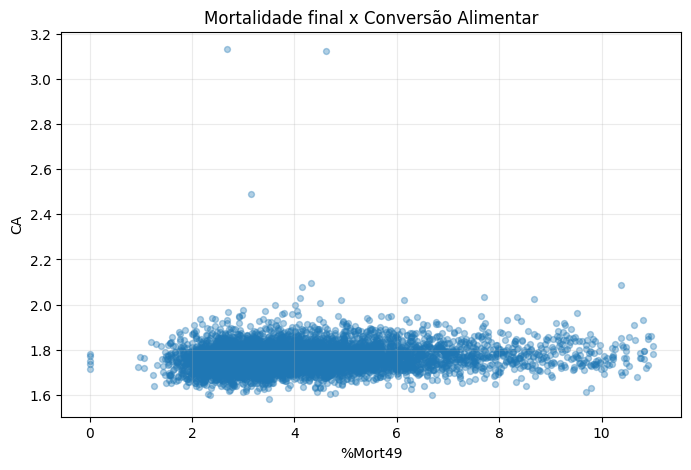

In [7]:
# 3.2 Visual: relação entre mortalidade final e CA
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["%Mort49"], df["CA"], alpha=0.35, s=18)
ax.set_title("Mortalidade final x Conversão Alimentar")
ax.set_xlabel("%Mort49")
ax.set_ylabel("CA")
ax.grid(True, alpha=0.25)
plt.show()


In [8]:
# 3.3 Variáveis numéricas mais correlacionadas com CA
corr_ca = df.corr(numeric_only=True)["CA"].sort_values()

print("Variáveis associadas a menor CA:")
display(corr_ca.head(8).to_frame("correlacao_com_CA"))

print("Variáveis associadas a maior CA:")
display(corr_ca.tail(8).to_frame("correlacao_com_CA"))


Variáveis associadas a menor CA:


,correlacao_com_CA
Aves Abatidas,-0.1565
Peso28,-0.1049
Ração Pré,-0.1033
Aves Alojadas,-0.1021
Ração Cres1,-0.0989
RaçãoInicial,-0.0840
Peso Abatido (kg),-0.0723
Sobra Racao,-0.0664


Variáveis associadas a maior CA:


,correlacao_com_CA
Ração Cres2,0.0434
%Mort42,0.0577
Ração Total,0.0828
mort,0.1433
%Mort49,0.1433
Ração Final,0.1902
Idade Média (dias),0.4794
CA,1.0000


**Insight de consultoria:** mortalidade final é um sinal importante, mas não deve ser vendida como causa única da piora de CA. A correlação bruta é alta, porém cai após o filtro de mortalidade extrema. A recomendação correta é tratar mortalidade como **sinal operacional de risco e custo**, combinada com peso, idade, ração e sobra.


# 4. Benchmark interno: onde a operação já performa melhor

**Pergunta de negócio:** existe uma referência interna atingível para reduzir custo?

A análise original apontou a `Regiao_13` como destaque. O bloco abaixo preserva essa investigação e acrescenta métricas de volume e sobra para tornar o benchmark acionável.


In [9]:
# 4.1 Ranking regional por CA, mortalidade, sobra e volume
resumo_regiao = (
    df.groupby("Regiao")
      .agg(
          lotes=("CA", "size"),
          CA_medio=("CA", "mean"),
          Mort49_media=("%Mort49", "mean"),
          Racao_total_kg=("Ração Total", "sum"),
          Sobra_racao_kg=("Sobra Racao", "sum"),
          Peso_abatido_kg=("Peso Abatido (kg)", "sum"),
          Aves_alojadas=("Aves Alojadas", "sum")
      )
      .assign(Sobra_pct=lambda x: x["Sobra_racao_kg"] / x["Racao_total_kg"])
      .sort_values("CA_medio")
)

benchmark_regiao = resumo_regiao.index[0]
ca_benchmark = resumo_regiao.loc[benchmark_regiao, "CA_medio"]
mort_benchmark = resumo_regiao["Mort49_media"].min()

print(f"Benchmark interno por CA: {benchmark_regiao}")
print(f"CA médio benchmark: {ca_benchmark:.4f}")
print(f"Menor Mort49 média regional: {mort_benchmark:.2f}%")

print("Melhores regiões por CA médio:")
display(resumo_regiao.head(8))

print("Piores regiões por CA médio:")
display(resumo_regiao.tail(5).sort_values("CA_medio", ascending=False))


Benchmark interno por CA: Regiao_13
CA médio benchmark: 1.7483
Menor Mort49 média regional: 3.34%
Melhores regiões por CA médio:


,lotes,CA_medio,Mort49_media,Racao_total_kg,Sobra_racao_kg,Peso_abatido_kg,Aves_alojadas,Sobra_pct
Regiao,,,,,,,,
Regiao_13,359,1.7483,3.3434,58463286,669878,33430530,10376005,0.0115
Regiao_8,264,1.7547,3.7913,42727750,814569,24366050,7662671,0.0191
Regiao_10,266,1.7549,4.3054,44405044,801839,25297600,8014669,0.0181
Regiao_11,363,1.7559,4.2495,62222209,1288501,35434510,11222290,0.0207
Regiao_4,686,1.7576,4.3581,114878936,1811502,65424720,20617411,0.0158
Regiao_5,354,1.7615,3.6663,47302508,992135,26896240,8525129,0.0210
Regiao_7,492,1.7620,4.5068,81927651,1740310,46487830,14813864,0.0212
Regiao_2,881,1.7622,4.5021,143592642,2747336,81520680,25825670,0.0191


Piores regiões por CA médio:


,lotes,CA_medio,Mort49_media,Racao_total_kg,Sobra_racao_kg,Peso_abatido_kg,Aves_alojadas,Sobra_pct
Regiao,,,,,,,,
Regiao_12,165,1.7912,4.3607,29198495,653588,16332370,5094095,0.0224
Regiao_14,13,1.7807,5.0803,2326878,32200,1304880,419100,0.0138
Regiao_15,25,1.7794,5.0217,4522206,100740,2540460,766072,0.0223
Regiao_6,423,1.7729,3.8499,73727859,922947,41612380,12989274,0.0125
Regiao_1,287,1.7709,4.3352,43168318,837598,24403630,7757654,0.0194


In [10]:
# 4.2 Leitura cruzada Região x Técnico — preserva a investigação original
# Ajuda a separar efeito de região, técnico e distribuição operacional.
regiao_tecnico = pd.crosstab(df["Regiao"], df["Tecnico"])
display(regiao_tecnico)


Tecnico,Tecnico_1,Tecnico_10,Tecnico_11,Tecnico_12,Tecnico_2,Tecnico_3,Tecnico_4,Tecnico_5,Tecnico_6,Tecnico_7,Tecnico_8,Tecnico_9
Regiao,,,,,,,,,,,,
Regiao_1,269,0,0,12,0,2,0,0,0,4,0,0
Regiao_10,0,0,2,0,0,0,0,264,0,0,0,0
Regiao_11,0,0,0,0,0,23,0,0,0,340,0,0
Regiao_12,0,0,0,0,0,9,0,0,0,156,0,0
Regiao_13,0,0,0,0,60,0,10,0,92,0,197,0
Regiao_14,0,0,0,8,4,0,1,0,0,0,0,0
Regiao_15,0,0,0,0,0,0,0,0,0,25,0,0
Regiao_2,16,0,14,273,289,10,27,27,209,2,9,5
Regiao_3,481,0,0,29,0,11,0,0,42,123,12,6


In [11]:
# 4.3 Ranking por técnico — cuidado: não interpretar como causalidade sem controlar mix de região/produtor
resumo_tecnico = (
    df.groupby("Tecnico")
      .agg(
          lotes=("CA", "size"),
          CA_medio=("CA", "mean"),
          Mort49_media=("%Mort49", "mean"),
          Sobra_pct=("Sobra Racao", lambda s: s.sum() / df.loc[s.index, "Ração Total"].sum())
      )
      .sort_values("CA_medio")
)

display(resumo_tecnico)


,lotes,CA_medio,Mort49_media,Sobra_pct
Tecnico,,,,
Tecnico_2,736,1.7511,4.3233,0.0178
Tecnico_10,65,1.7542,4.0543,0.0192
Tecnico_5,718,1.7571,3.8428,0.0213
Tecnico_8,679,1.7608,4.1747,0.0201
Tecnico_6,789,1.7648,4.0829,0.0130
Tecnico_11,384,1.7652,4.1849,0.0190
Tecnico_7,717,1.7658,4.5175,0.0217
Tecnico_4,352,1.7681,4.3624,0.0143
Tecnico_12,332,1.7681,4.6077,0.0209


**Insight de consultoria:** a `Regiao_13` é um benchmark interno, não uma meta arbitrária. A próxima etapa não é “copiar o número”, mas investigar o playbook operacional da região: manejo inicial, ambiência, vazio sanitário, densidade, origem/pintinho, rotina do técnico, granularidade do arraçoamento e controle de sobra.


# 5. Modelo estrutural: por que cadastro não explica tudo

**Pergunta de negócio:** conseguimos prever mortalidade final apenas com variáveis estruturais, antes do ciclo evoluir?

A investigação original mostrou R² baixo. Isso é importante: indica que região, técnico, instalação, nutrição, genética, densidade e peso do pintinho ajudam, mas não capturam a dinâmica real da criação. O custo começa a aparecer quando observamos os primeiros sinais do lote.


In [12]:
# 5.1 Funções utilitárias de modelagem — versão enxuta e reutilizável
train_idx, test_idx = train_test_split(
    np.arange(len(df_model)),
    test_size=0.2,
    random_state=RANDOM_STATE
)

def prepara_X(base: pd.DataFrame, colunas: list[str]) -> pd.DataFrame:
    # One-hot encoding padronizado para variáveis categóricas e preenchimento de NaNs.
    return pd.get_dummies(base[colunas], dummy_na=True).fillna(0)

def treina_rf_regressor(X: pd.DataFrame, y: pd.Series, *, n_estimators=40, max_depth=10, min_samples_leaf=8):
    # Treina Random Forest com parâmetros controlados para evitar células lentas/travadas.
    modelo = RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        max_samples=0.70,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    modelo.fit(X.iloc[train_idx], y.iloc[train_idx])
    pred = modelo.predict(X.iloc[test_idx])
    metricas = {
        "R2": r2_score(y.iloc[test_idx], pred),
        "MAE": mean_absolute_error(y.iloc[test_idx], pred),
        "n_features_modelo": X.shape[1]
    }
    importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values(ascending=False)
    return modelo, pred, metricas, importancias


In [13]:
# 5.2 Modelo estrutural para prever %Mort49
features_estruturais = [
    "Produtor", "Regiao", "Tecnico", "Num_Galpao", "Tipo_Instalacao", "Nutricao", "Área",
    "Genetica", "Origem", "Peso Pintinho (kg)", "Aves Alojadas", "Vazio (dias)",
    "Densidade (aves/m²)", "Idade Média (dias)"
]

X_estrutural = prepara_X(df_model, features_estruturais)
y_mort49 = df["%Mort49"]

modelo_estrutural, pred_estrutural, metricas_estrutural, imp_estrutural = treina_rf_regressor(
    X_estrutural,
    y_mort49,
    n_estimators=40,
    max_depth=10,
    min_samples_leaf=8
)

print("Métricas do modelo estrutural para %Mort49")
display(pd.DataFrame([metricas_estrutural]))

print("Top 20 variáveis/importâncias")
display(imp_estrutural.head(20).to_frame("importancia"))


Métricas do modelo estrutural para %Mort49


,R2,MAE,n_features_modelo
0,0.0953,1.2617,422


Top 20 variáveis/importâncias


,importancia
Idade Média (dias),0.1270
Peso Pintinho (kg),0.0993
Vazio (dias),0.0785
Aves Alojadas,0.0765
Regiao_Regiao_13,0.0752
Densidade (aves/m²),0.0724
Tipo_Instalacao_Tipo_8,0.0432
Genetica_G_4,0.0360
Tecnico_Tecnico_5,0.0330
Área,0.0318


**Leitura analítica:** o modelo estrutural tem baixo poder explicativo. Para o cliente, isso é uma ótima descoberta: o problema não será resolvido apenas trocando cadastro, genética ou técnico. A solução precisa monitorar o comportamento do lote logo no início do ciclo.


# 6. Decomposição da mortalidade: onde a perda nasce

**Pergunta de negócio:** em qual janela do ciclo a mortalidade se concentra?

A mortalidade final é acumulada. Por isso, em vez de olhar apenas `%Mort49`, decompomos a mortalidade em períodos semanais. Essa análise preserva a etapa original e transforma o insight em uma decisão operacional: quando intervir.


In [14]:
# 6.1 Mortalidade incremental por período
df["Mort_0_7"] = df["%Mort7"]
df["Mort_7_14"] = df["%Mort14"] - df["%Mort7"]
df["Mort_14_21"] = df["%Mort21"] - df["%Mort14"]
df["Mort_21_28"] = df["%Mort28"] - df["%Mort21"]
df["Mort_28_35"] = df["%Mort35"] - df["%Mort28"]
df["Mort_35_42"] = df["%Mort42"] - df["%Mort35"]
df["Mort_42_49"] = df["%Mort49"] - df["%Mort42"]

mapa_periodos = {
    "Mort_0_7": "0–7 dias",
    "Mort_7_14": "7–14 dias",
    "Mort_14_21": "14–21 dias",
    "Mort_21_28": "21–28 dias",
    "Mort_28_35": "28–35 dias",
    "Mort_35_42": "35–42 dias",
    "Mort_42_49": "42–49 dias",
}

mort_periodos = (
    df[list(mapa_periodos.keys())]
      .mean()
      .rename(index=mapa_periodos)
      .reset_index()
      .rename(columns={"index": "periodo", 0: "mortalidade_media_pp"})
)
mort_periodos["participacao_na_Mort49_media"] = mort_periodos["mortalidade_media_pp"] / df["%Mort49"].mean()
mort_periodos = mort_periodos.sort_values("mortalidade_media_pp", ascending=False)

display(mort_periodos)


,periodo,mortalidade_media_pp,participacao_na_Mort49_media
0,0–7 dias,1.3263,0.3134
6,42–49 dias,0.7164,0.1693
5,35–42 dias,0.6149,0.1453
1,7–14 dias,0.5007,0.1183
4,28–35 dias,0.4177,0.0987
2,14–21 dias,0.3591,0.0849
3,21–28 dias,0.2966,0.0701


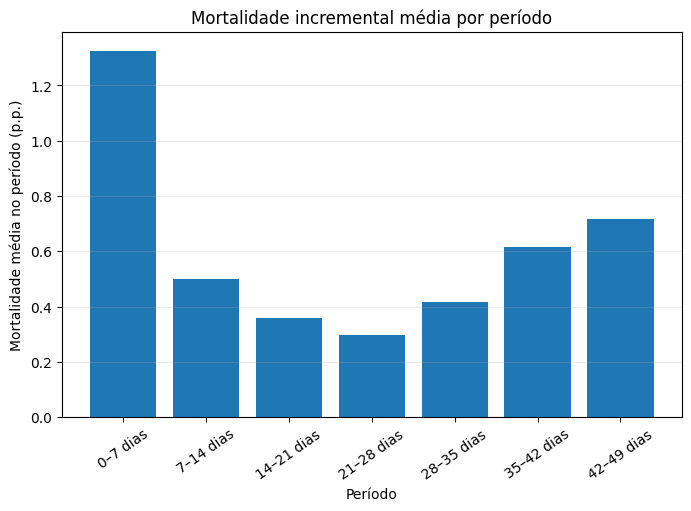

In [15]:
# 6.2 Visual: mortalidade incremental média por período
fig, ax = plt.subplots(figsize=(8, 5))
ordem_cronologica = ["0–7 dias", "7–14 dias", "14–21 dias", "21–28 dias", "28–35 dias", "35–42 dias", "42–49 dias"]
plot_data = mort_periodos.set_index("periodo").loc[ordem_cronologica]
ax.bar(plot_data.index, plot_data["mortalidade_media_pp"])
ax.set_title("Mortalidade incremental média por período")
ax.set_xlabel("Período")
ax.set_ylabel("Mortalidade média no período (p.p.)")
ax.tick_params(axis="x", rotation=35)
ax.grid(True, axis="y", alpha=0.25)
plt.show()


**Insight de consultoria:** a primeira semana concentra a maior parcela média das perdas. Logo, a intervenção econômica não deve esperar o fechamento do lote. O cliente precisa de uma rotina D+7 para antecipar manejo, sanidade, ambiência, água e ração inicial.


# 7. Previsão precoce: célula reestruturada e sem travamento

**Pergunta de negócio:** com informações até cada semana, quanto conseguimos prever da mortalidade final?

A célula anterior parecia entrar em loop infinito porque treinava **6 Random Forests de 500 árvores**, com `get_dummies` dentro de cada iteração e impressão extensa de importâncias. Isso não é um loop lógico infinito, mas um problema de desempenho e legibilidade.

A versão abaixo corrige isso de quatro formas:

1. Usa o mesmo `train/test split` para todos os dias, garantindo comparação justa.
2. Reduz o número de árvores para um patamar suficiente para análise consultiva.
3. Controla `max_depth`, `min_samples_leaf` e `max_samples`, evitando árvores grandes demais.
4. Retorna uma tabela única de métricas, em vez de imprimir blocos repetidos.


In [16]:
# 7.1 Definição das features disponíveis até cada dia
features_base_previsao = [
    "Regiao", "Tecnico", "Tipo_Instalacao", "Nutricao", "Genetica", "Origem",
    "Peso Pintinho (kg)", "Aves Alojadas", "Vazio (dias)", "Densidade (aves/m²)", "Área"
]

dias_semanais = [7, 14, 21, 28, 35, 42]

def features_ate_dia(dia: int) -> list[str]:
    # Retorna somente variáveis que estariam disponíveis até o dia informado.
    pesos = [f"Peso{d}" for d in dias_semanais if d <= dia]
    mortalidades = [f"%Mort{d}" for d in dias_semanais if d <= dia]
    return features_base_previsao + pesos + mortalidades


In [17]:
# 7.2 Função otimizada para substituir a célula que travava
def modelo_mort49_ate_dia_otimizado(df_base: pd.DataFrame, dia: int) -> dict:
    # Treina um modelo rápido e comparável para prever %Mort49 com dados disponíveis até o dia.
    # Esta função substitui a versão pesada com 500 árvores por dia.
    # O objetivo aqui é análise consultiva e priorização operacional, não tuning final de produção.
    colunas = features_ate_dia(dia)
    X = prepara_X(df_base, colunas)
    y = df["%Mort49"]

    modelo, pred, metricas, importancias = treina_rf_regressor(
        X,
        y,
        n_estimators=40,
        max_depth=10,
        min_samples_leaf=8
    )

    return {
        "dia": dia,
        "modelo": modelo,
        "pred": pred,
        "r2": metricas["R2"],
        "mae": metricas["MAE"],
        "n_features_modelo": metricas["n_features_modelo"],
        "importancias": importancias
    }


In [18]:
# 7.3 Loop reestruturado: tabela única, rápida e legível para o analista
# Incluímos dia 0 como baseline estrutural: antes de entrar Peso7/%Mort7.
dias_avaliados = [0, 7, 14, 21, 28, 35, 42]

resultados = [modelo_mort49_ate_dia_otimizado(df_model, dia) for dia in dias_avaliados]

resultado_previsao = pd.DataFrame([
    {
        "dia_disponivel": r["dia"],
        "R2_para_prever_Mort49": r["r2"],
        "MAE_pp_mortalidade": r["mae"],
        "n_features_modelo": r["n_features_modelo"]
    }
    for r in resultados
])

display(resultado_previsao)


,dia_disponivel,R2_para_prever_Mort49,MAE_pp_mortalidade,n_features_modelo
0,0,0.0878,1.2724,86
1,7,0.4882,0.9199,88
2,14,0.5870,0.8071,90
3,21,0.6235,0.7511,92
4,28,0.6715,0.6901,94
5,35,0.7901,0.5463,96
6,42,0.9061,0.3496,98


In [19]:
# 7.4 Importâncias principais por dia, em formato compacto
importancias_top = []
for r in resultados:
    top = r["importancias"].head(8).reset_index()
    top.columns = ["variavel", "importancia"]
    top.insert(0, "dia_disponivel", r["dia"])
    importancias_top.append(top)

importancias_top = pd.concat(importancias_top, ignore_index=True)
display(importancias_top)


,dia_disponivel,variavel,importancia
0,0,Peso Pintinho (kg),0.1223
1,0,Aves Alojadas,0.1162
2,0,Vazio (dias),0.1065
3,0,Densidade (aves/m²),0.1034
4,0,Regiao_Regiao_13,0.0755
5,0,Área,0.0468
6,0,Tipo_Instalacao_Tipo_8,0.0462
7,0,Genetica_G_4,0.0404
8,7,%Mort7,0.7789
9,7,Vazio (dias),0.0268


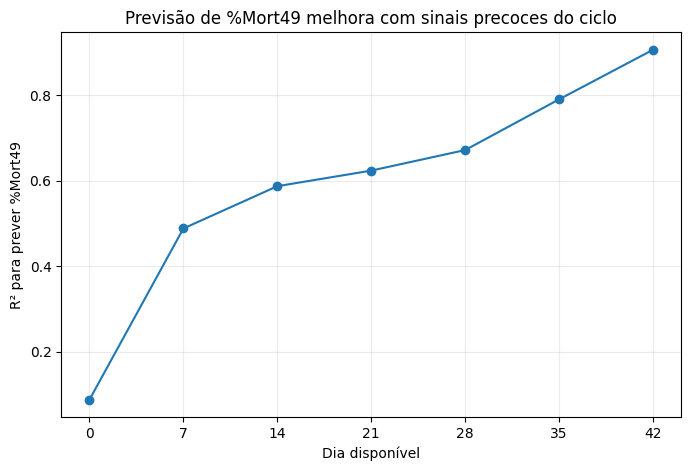

In [20]:
# 7.5 Visual: ganho preditivo conforme o ciclo avança
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(resultado_previsao["dia_disponivel"], resultado_previsao["R2_para_prever_Mort49"], marker="o")
ax.set_title("Previsão de %Mort49 melhora com sinais precoces do ciclo")
ax.set_xlabel("Dia disponível")
ax.set_ylabel("R² para prever %Mort49")
ax.set_xticks(dias_avaliados)
ax.grid(True, alpha=0.25)
plt.show()


**Insight de consultoria:** o salto acontece já no D+7. Antes do ciclo, o cadastro estrutural explica pouco. Ao incluir `%Mort7` e `Peso7`, o modelo já separa lotes de risco. Isso sustenta a solução: **score de risco D+7 com fila de intervenção técnica**.


# 8. Fila de priorização operacional no D+7

**Pergunta de negócio:** como transformar previsão em ação de redução de custo?

O modelo não deve ser entregue como “caixa-preta”. A saída consultiva é uma fila de prioridade: lotes com maior risco previsto no D+7 entram em vermelho e recebem intervenção em até 48 horas.


In [21]:
# 8.1 Avaliação do top quartil de risco D+7
resultado_d7 = next(r for r in resultados if r["dia"] == 7)
y_test = y_mort49.iloc[test_idx].reset_index(drop=True)

score_d7 = pd.DataFrame({
    "Mort49_real": y_test,
    "Mort49_prevista_D7": resultado_d7["pred"]
})

score_d7["quartil_risco_D7"] = pd.qcut(
    score_d7["Mort49_prevista_D7"],
    q=4,
    labels=["Q1 baixo", "Q2", "Q3", "Q4 alto"]
)

real_top_quartil = score_d7["Mort49_real"] >= score_d7["Mort49_real"].quantile(0.75)
pred_top_quartil = score_d7["quartil_risco_D7"].astype(str).eq("Q4 alto")

precisao_top_q4 = precision_score(real_top_quartil, pred_top_quartil)
recall_top_q4 = recall_score(real_top_quartil, pred_top_quartil)

resumo_quartil_d7 = (
    score_d7.groupby("quartil_risco_D7", observed=True)
            .agg(
                lotes_teste=("Mort49_real", "size"),
                Mort49_prevista_media=("Mort49_prevista_D7", "mean"),
                Mort49_real_media=("Mort49_real", "mean"),
                Mort49_real_mediana=("Mort49_real", "median")
            )
)

print(f"Precisão do quartil vermelho D+7: {precisao_top_q4:.1%}")
print(f"Recall do quartil vermelho D+7: {recall_top_q4:.1%}")
display(resumo_quartil_d7)


Precisão do quartil vermelho D+7: 61.9%
Recall do quartil vermelho D+7: 61.7%


,lotes_teste,Mort49_prevista_media,Mort49_real_media,Mort49_real_mediana
quartil_risco_D7,,,,
Q1 baixo,287,3.0280,3.0965,2.8795
Q2,286,3.6396,3.6995,3.4619
Q3,286,4.2833,4.3284,4.0439
Q4 alto,286,5.8829,5.9936,5.7126


**Leitura operacional:** o quartil vermelho do D+7 concentra lotes com mortalidade final muito maior. A ação recomendada não é intervir em todos; é priorizar os lotes de maior risco e maior impacto econômico. Isso reduz custo de visita técnica e aumenta retorno da operação.


# 9. Potencial econômico físico: CA, ração e sobra

**Pergunta de negócio:** qual é o tamanho do prêmio operacional?

Como a base não traz preço por kg de ração nem margem por ave, não devemos inventar um valor financeiro. A abordagem correta é estimar o potencial físico: toneladas de ração em excesso frente ao benchmark, toneladas de sobra e aves potencialmente preserváveis. Depois, o cliente converte em R$ com seus preços reais.


In [22]:
# 9.1 Dimensionamento físico do potencial de economia
impacto = df.copy()
impacto["gap_CA_vs_benchmark"] = impacto["CA"] - ca_benchmark
impacto["excesso_racao_kg_vs_benchmark"] = np.maximum(impacto["gap_CA_vs_benchmark"], 0) * impacto["Peso Abatido (kg)"]
impacto["aves_perdidas_vs_benchmark"] = np.maximum(
    impacto["Aves Alojadas"] * ((impacto["%Mort49"] - mort_benchmark) / 100),
    0
)

excesso_racao_t = impacto["excesso_racao_kg_vs_benchmark"].sum() / 1000
sobra_racao_t = impacto["Sobra Racao"].sum() / 1000
aves_potenciais = impacto["aves_perdidas_vs_benchmark"].sum()

cenarios = pd.DataFrame({
    "cenario": ["Capturar 25% do gap", "Capturar 50% do gap", "Capturar 100% do gap teórico"],
    "reducao_excesso_racao_t": [excesso_racao_t * 0.25, excesso_racao_t * 0.50, excesso_racao_t],
    "reducao_sobra_racao_t": [sobra_racao_t * 0.25, sobra_racao_t * 0.50, sobra_racao_t],
    "aves_potencialmente_preservadas": [aves_potenciais * 0.25, aves_potenciais * 0.50, aves_potenciais]
})

print(f"Excesso físico de ração vs benchmark interno: {excesso_racao_t:,.1f} t")
print(f"Sobra total de ração registrada: {sobra_racao_t:,.1f} t")
print(f"Aves potencialmente preserváveis vs mortalidade benchmark: {aves_potenciais:,.0f}")
display(cenarios)


Excesso físico de ração vs benchmark interno: 15,031.1 t
Sobra total de ração registrada: 17,315.3 t
Aves potencialmente preserváveis vs mortalidade benchmark: 1,891,281


,cenario,reducao_excesso_racao_t,reducao_sobra_racao_t,aves_potencialmente_preservadas
0,Capturar 25% do gap,"3,757.7747","4,328.8202","472,820.2370"
1,Capturar 50% do gap,"7,515.5495","8,657.6405","945,640.4740"
2,Capturar 100% do gap teórico,"15,031.0989","17,315.2810","1,891,280.9480"


In [23]:
# 9.2 Concentração do excesso: quantos lotes explicam a maior parte do problema?
impacto_ordenado = impacto.sort_values("excesso_racao_kg_vs_benchmark", ascending=False).reset_index(drop=True)
total_excesso = impacto_ordenado["excesso_racao_kg_vs_benchmark"].sum()

concentracao = []
for percentual_lotes in [0.10, 0.20, 0.30]:
    n_lotes = int(np.ceil(percentual_lotes * len(impacto_ordenado)))
    excesso_capturado = impacto_ordenado.head(n_lotes)["excesso_racao_kg_vs_benchmark"].sum() / total_excesso
    concentracao.append({
        "% lotes priorizados": f"{percentual_lotes:.0%}",
        "lotes": n_lotes,
        "% excesso de ração capturado": excesso_capturado
    })

concentracao = pd.DataFrame(concentracao)
display(concentracao)


,% lotes priorizados,lotes,% excesso de ração capturado
0,10%,573,0.4346
1,20%,1145,0.6682
2,30%,1718,0.8267


**Insight econômico:** a oportunidade é concentrada. Os 20% piores lotes por excesso físico explicam aproximadamente dois terços do excesso de ração. Portanto, a solução mais barata para o cliente não é “analisar tudo”, mas criar uma régua de priorização por impacto.


# 10. Solução recomendada para o cliente

## Proposta: Central de Controle de Lotes Críticos

A entrega da consultoria deve ser um **processo de decisão**, não apenas um modelo. A solução proposta combina três rotinas:

### 1. Alerta D+7 de mortalidade
Rodar semanalmente o score para todos os lotes que completaram 7 dias. Classificar os lotes em verde, amarelo e vermelho. O vermelho recebe ação imediata.

### 2. Playbook Região 13
Usar a `Regiao_13` como benchmark interno. Investigar e documentar manejo inicial, origem dos pintinhos, rotinas técnicas, densidade, vazio sanitário, ambiência, arraçoamento inicial e controle de sobra.

### 3. Gestão de custo de ração
Monitorar excesso de CA vs benchmark e sobra de ração. A régua operacional deve priorizar lotes/regiões que combinam: alto risco D+7, alto gap de CA, alta sobra e grande volume.

| Gatilho | Ação recomendada | KPI de acompanhamento |
|---|---|---|
| `%Mort7` acima do P75 ou score D+7 no quartil vermelho | Visita técnica/priorização em até 48h; checklist de ambiência, água, ração pré/inicial, cama e sanidade | `%Mort14`, `%Mort21`, evolução do score e mortalidade acumulada |
| Região/produtor com gap de CA vs benchmark | Benchmark assistido: comparar rotina técnica, densidade, vazio sanitário, genética/origem e manejo inicial | CA médio, gap de CA, kg de ração excedente e peso abatido |
| Sobra de ração acima do P75 ou tendência crescente | Revisar pedido, entrega, manejo de comedouros, ajuste por fase e política de devolução/reaproveitamento | Sobra kg, sobra %, custo evitado estimado |
| Top 20% lotes por excesso físico de ração | Foco de melhoria contínua e auditoria operacional | % do excesso capturado e economia física em toneladas |


# 11. Roadmap de implantação sugerido

## Piloto de 90 dias

**Primeiros 15 dias — preparação**
- Validar preços de ração por fase, regra de sobra e margem por ave/kg.
- Confirmar regras de negócio com equipe técnica.
- Padronizar coleta de `%Mort7`, `Peso7`, ração inicial e causas de mortalidade.

**Dias 16–45 — piloto controlado**
- Rodar score D+7 semanalmente.
- Intervir apenas no grupo vermelho.
- Registrar ação executada, responsável, prazo e resultado observado em D+14/D+21.

**Dias 46–90 — medição de impacto**
- Comparar lotes vermelhos intervencionados contra histórico/controle.
- Medir redução de mortalidade, CA e sobra.
- Converter toneladas físicas em R$ usando preços reais do cliente.

**Critério de sucesso do piloto:** capturar ao menos 25% do gap físico priorizado nos lotes críticos e comprovar melhora operacional antes de expandir para toda a base.


# 12. Perguntas necessárias para fechar o business case financeiro

Para transformar toneladas e aves em R$, precisamos validar com o cliente:

1. Qual é o **preço médio por kg de ração**, idealmente por fase: pré, inicial, crescimento 1, crescimento 2 e final?
2. A coluna `Sobra Racao` representa sobra física reaproveitável, perda, devolução ao estoque ou ajuste contábil?
3. Qual é a **margem econômica por ave abatida** ou por kg abatido?
4. Qual é o custo de uma visita/intervenção técnica e qual a capacidade semanal da equipe?
5. O cliente aceita uma política de priorização por risco, isto é, intervir primeiro nos lotes vermelhos e não em todos os lotes?
6. As causas de mortalidade são registradas? Se sim, quais categorias existem?
7. Há dados de temperatura, umidade, consumo de água, consumo diário de ração, medicação, qualidade da cama e ambiência?
8. Existem restrições operacionais por região, equipe, granja ou calendário que limitem a intervenção em até 48h?

Sem essas respostas, a recomendação deve ser apresentada como **potencial físico de economia**, não como promessa financeira fechada.


# 13. Sugestão de slides para apresentação ao cliente

| Slide | Título | Mensagem principal | Visual recomendado |
|---:|---|---|---|
| 1 | O custo nasce antes do fechamento do lote | Mortalidade final é consequência de sinais que aparecem cedo | Linha do tempo 0–49 dias |
| 2 | O que investigamos | Base com lotes, pesos, mortalidade acumulada, ração e CA | Mapa das variáveis |
| 3 | Governança da base | Há outliers e possíveis problemas de unidade; a análise foi protegida | Tabela de qualidade |
| 4 | Mortalidade × CA: insight refinado | A correlação bruta é influenciada por extremos; mortalidade importa, mas não explica tudo | Scatter Mort49 × CA + correlações |
| 5 | Benchmark interno existe | Região 13 combina melhor CA e baixa mortalidade | Ranking regional |
| 6 | O tamanho do prêmio operacional | Gap de CA e sobra mostram toneladas físicas com potencial de captura | Cenários 25/50/100% |
| 7 | Onde a mortalidade se concentra | A primeira semana é a maior janela de perda média | Barras por período |
| 8 | Modelo estrutural não basta | Cadastro do lote explica pouco; precisamos observar o início do ciclo | Card do R² estrutural |
| 9 | D+7 já separa risco | Score no dia 7 identifica lotes de maior mortalidade final | Curva R² por dia |
| 10 | Como operar o alerta | Classificação verde/amarelo/vermelho e intervenção em 48h | Fluxo operacional |
| 11 | Playbook Região 13 | Replicar práticas internas de melhor desempenho | Comparativo Região 13 vs regiões críticas |
| 12 | Roadmap de implantação | Piloto de 90 dias, medição e expansão | Plano 15/45/90 dias |


# 14. Sugestão de dashboards

## Dashboard 1 — Visão executiva
KPIs: CA médio, `%Mort49` médio, `%Mort7` médio, toneladas de excesso de ração vs benchmark, sobra de ração, lotes em risco vermelho e economia potencial 25/50%.

## Dashboard 2 — Benchmark regional
Ranking de regiões por CA, mortalidade, sobra %, volume de aves e excesso físico de ração. Filtros: técnico, produtor, origem, genética e tipo de instalação.

## Dashboard 3 — Alerta D+7
Lista dos lotes que completaram 7 dias, com score de risco, classificação verde/amarelo/vermelho, mortalidade D+7, peso D+7, técnico responsável, produtor e ação recomendada.

## Dashboard 4 — Gestão de ração
Ração por fase, sobra em kg e %, CA vs benchmark, top lotes com maior excesso físico, evolução mensal e regiões com maior oportunidade.

## Dashboard 5 — Drill-down do lote
Linha do tempo do lote: peso semanal, mortalidade acumulada, mortalidade incremental por fase, ração por fase, status da intervenção e resultado final.


# 15. Conclusão consultiva

A mortalidade não é um evento isolado do final do ciclo. Ela começa cedo, acumula ao longo da criação e impacta diretamente o desempenho final do lote.

A investigação sustenta quatro decisões:

1. **Usar a Região 13 como benchmark interno**, porque ela demonstra que há padrão operacional atingível dentro da própria empresa.
2. **Não depender apenas de variáveis estruturais**, pois o modelo pré-ciclo explica pouco da mortalidade final.
3. **Atuar no D+7**, porque a primeira semana concentra a maior perda média e já fornece sinal preditivo relevante.
4. **Priorizar por impacto econômico**, porque poucos lotes explicam grande parte do excesso físico de ração.

**Recomendação final:** implantar um piloto de 90 dias com score D+7, comitê semanal de lotes vermelhos, checklist técnico padronizado, playbook da Região 13 e dashboard de custo evitável. A meta inicial deve ser capturar 25% do gap físico de ração nos lotes críticos e medir redução de mortalidade/CA antes da expansão.
